CONSIGNAS

###1) Carga y descripción inicial del dataset

a) Lea el archivo listings.csv.gz correspondiente a la ciudad asignada.

In [1]:
import pandas as pd
import numpy as np

Se utilizará el csv listingsjunio dado que el de septiembre no contiene los valores de la variable objetivo price.

In [2]:
df = pd.read_csv("/content/listingsjunio.csv.gz")
df.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,3109,https://www.airbnb.com/rooms/3109,20250606142312,2025-06-20,city scrape,zen and calm,Lovely Appartment with one bedroom with a Quee...,Good restaurants<br />very close the Montparna...,https://a0.muscache.com/pictures/miso/Hosting-...,3631,...,5.00,5.00,5.00,7511409139079,f,1,1,0,0,0.08
1,5396,https://www.airbnb.com/rooms/5396,20250606142312,2025-06-19,city scrape,Your perfect Paris studio on Île Saint-Louis,"Cozy, well-appointed and graciously designed s...","You are within walking distance to the Louvre,...",https://a0.muscache.com/pictures/52413/f9bf76f...,7903,...,4.85,4.95,4.59,7510402838018,f,1,1,0,0,2.32
2,7397,https://www.airbnb.com/rooms/7397,20250606142312,2025-06-20,city scrape,MARAIS - 2ROOMS APT - 2/4 PEOPLE,"VERY CONVENIENT, WITH THE BEST LOCATION !",NaN,https://a0.muscache.com/pictures/67928287/330b...,2626,...,4.89,4.94,4.74,7510400829623,f,1,1,0,0,2.20
3,7964,https://www.airbnb.com/rooms/7964,20250606142312,2025-06-18,previous scrape,Sunny apartment with balcony,"We are renting our a spacious, sunny fully fur...",NaN,https://a0.muscache.com/pictures/miso/Hosting-...,22155,...,5.00,5.00,5.00,7510903576564,f,1,1,0,0,0.03
4,9359,https://www.airbnb.com/rooms/9359,20250606142312,2025-06-18,city scrape,"Cozy, Central Paris: WALK or VELIB EVERYWHERE !",Location! Location! Location! Just bring your ...,NaN,https://a0.muscache.com/pictures/c2965945-061f...,28422,...,NaN,NaN,NaN,"Available with a mobility lease only (""bail mo...",f,1,1,0,0,NaN


b) ¿Qué puede decir acerca de la estructura del dataset? Mencione cantidad de filas
y columnas, tipos de variables, presencia de datos faltantes y de qué trata el
conjunto de datos en términos generales.

In [3]:
df.shape

(84055, 79)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 84055 entries, 0 to 84054
Data columns (total 79 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            84055 non-null  int64  
 1   listing_url                                   84055 non-null  object 
 2   scrape_id                                     84055 non-null  int64  
 3   last_scraped                                  84055 non-null  object 
 4   source                                        84055 non-null  object 
 5   name                                          84055 non-null  object 
 6   description                                   81177 non-null  object 
 7   neighborhood_overview                         41178 non-null  object 
 8   picture_url                                   84054 non-null  object 
 9   host_id                                       84055 non-null 

In [5]:
df.columns[df.isnull().all()].tolist()

['neighbourhood_group_cleansed', 'calendar_updated']

In [6]:
sacando_columnas = df.columns[df.isnull().all()].tolist()
print(f"Columnas a eliminar por estar completamente vacías: {sacando_columnas}")
df = df.drop(columns=sacando_columnas)
print(f"Nueva forma del DataFrame después de eliminar columnas vacías: {df.shape}")

Columnas a eliminar por estar completamente vacías: ['neighbourhood_group_cleansed', 'calendar_updated']
Nueva forma del DataFrame después de eliminar columnas vacías: (84055, 77)


El conjunto de datos nos muestra las distintas características (79 columnas) que poseen los distintos airbnb provistos en las 84055 filas.
Estos datos se dividen en 24 columnas del tipo int, 35 objetc y 20 float, de las cuales faltan datos de 2, 'neighbourhood_group_cleansed' y 'calendar_updated', por eso fueron eliminadas.

c) Identifique la variable objetivo price. ¿En qué formato se encuentra originalmente?
Realice las transformaciones necesarias para convertirla en una variable
numérica.


In [7]:
df["price"]

,price
0,$135.00
1,$114.00
2,$149.00
3,NaN
4,$75.00
...,...
84050,$78.00
84051,$89.00
84052,$105.00
84053,$100.00


In [8]:
df['price'] = df['price'].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False)
df['price'] = pd.to_numeric(df['price'], errors='coerce')

df['price'].head()


,price
0,135.0
1,114.0
2,149.0
3,NaN
4,75.0


Price se encontraba en formato object y fue transformado a float

d) Elimine observaciones sin precio o con precio igual o menor a cero, si las hubiera

In [9]:
df_limpio = df.dropna(subset=['price'])
df_limpio = df_limpio[df_limpio['price'] > 0]
print(f"Dimensiones del DataFrame después de la limpieza: {df_limpio.shape}")

Dimensiones del DataFrame después de la limpieza: (53963, 77)


Con dopna eliminamos los NaN y luego eliminamos los precios mayores o igual a cero

###2) Análisis exploratorio


a) Obtenga estadísticas descriptivas para la variable objetivo price. Incluya media,
mediana, desvío estándar, mínimo, máximo y percentiles relevantes

In [10]:
df_limpio['price'].describe()

,price
count,53963.000000
mean,285.263384
std,688.616441
min,8.000000
25%,104.000000
50%,161.000000
75%,277.000000
max,30814.000000


b) Realice un histograma de price. ¿Qué puede decir acerca de su distribución?
¿Observa asimetría, valores extremos o concentración en ciertos rangos?


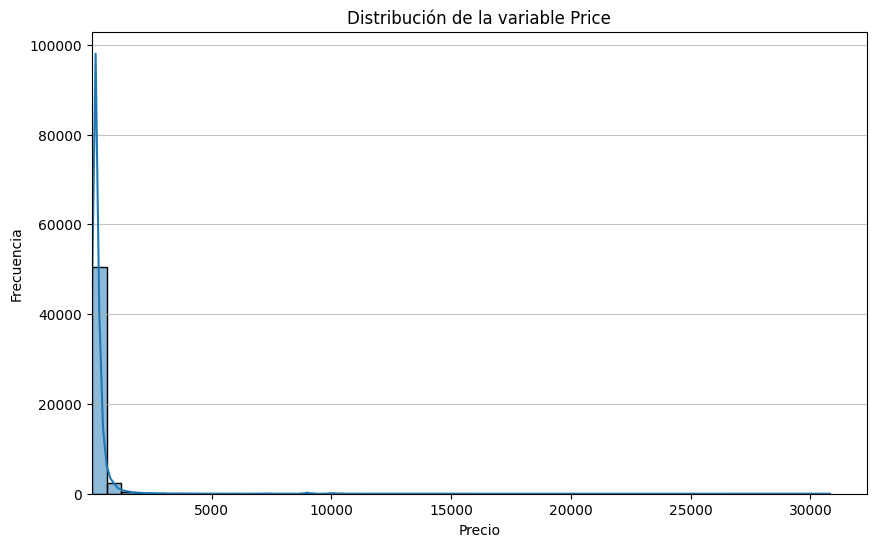

In [11]:
import matplotlib.pyplot as plot
import seaborn as sns

plot.figure(figsize=(10, 6))
sns.histplot(df_limpio['price'], bins=50, kde=True)
plot.title('Distribución de la variable Price')
plot.xlabel('Precio')
plot.ylabel('Frecuencia')
plot.xlim(left=df_limpio['price'].min())
plot.grid(axis='y', alpha=0.75)
plot.show()

### Histograma con enfoque en la concentración de precios

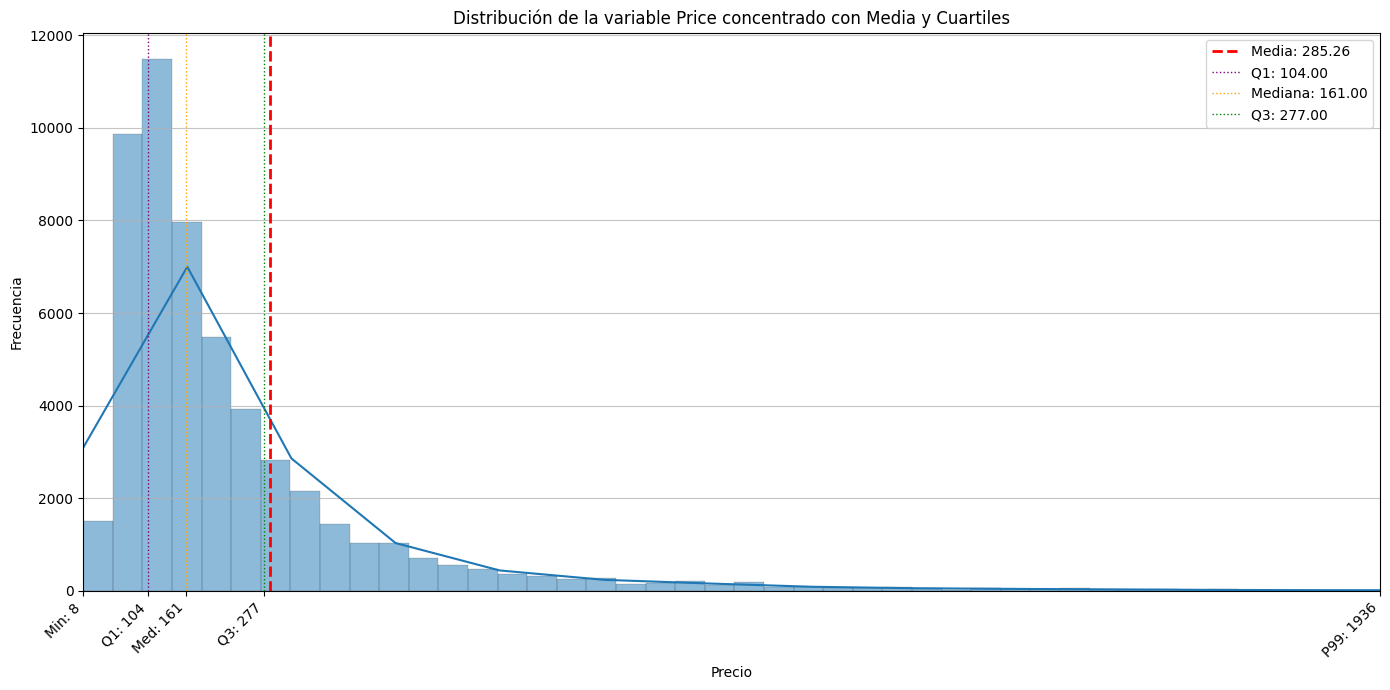

In [12]:
plot.figure(figsize=(14, 7))
sns.histplot(df_limpio['price'], bins=700, kde=True) # Aumentar el número de bins
plot.title('Distribución de la variable Price concentrado con Media y Cuartiles')
plot.xlabel('Precio')
plot.ylabel('Frecuencia')

media = df_limpio['price'].mean()
q1 = df_limpio['price'].quantile(0.25)
mediana = df_limpio['price'].quantile(0.50)
q3 = df_limpio['price'].quantile(0.75)
x_max = df_limpio['price'].quantile(0.99)
plot.xlim(left=df_limpio['price'].min(), right=x_max)

plot.axvline(media, color='red', linestyle='dashed', linewidth=2, label=f'Media: {media:.2f}')

if q1 <= x_max: plot.axvline(q1, color='purple', linestyle='dotted', linewidth=1, label=f'Q1: {q1:.2f}')
if mediana <= x_max: plot.axvline(mediana, color='orange', linestyle='dotted', linewidth=1, label=f'Mediana: {mediana:.2f}')
if q3 <= x_max: plot.axvline(q3, color='green', linestyle='dotted', linewidth=1, label=f'Q3: {q3:.2f}')

plot.legend()

quartile_positions_filtered = [pos for pos in [df_limpio['price'].min(), q1, mediana, q3] if pos <= x_max]
quartile_labels_filtered = [f'Min: {df_limpio['price'].min():.0f}', f'Q1: {q1:.0f}', f'Med: {mediana:.0f}', f'Q3: {q3:.0f}']
quartile_labels_filtered = [label for label, pos in zip(quartile_labels_filtered, [df_limpio['price'].min(), q1, mediana, q3]) if pos <= x_max]

if x_max not in quartile_positions_filtered:
    quartile_positions_filtered.append(x_max)
    quartile_labels_filtered.append(f'P99: {x_max:.0f}')

sorted_ticks = sorted(zip(quartile_positions_filtered, quartile_labels_filtered))
quartile_positions_filtered, quartile_labels_filtered = zip(*sorted_ticks)

plot.xticks(list(quartile_positions_filtered), list(quartile_labels_filtered), rotation=45, ha='right')
plot.grid(axis='y', alpha=0.75)
plot.tight_layout()
plot.show()

Analisis del histograma de price:
La linea roja nos muestra la media
La distribución es fuertemente asimétrica a la derecha (sesgada positivamente). Esto nos dice que la mayoría de los precios se concentran en valores más bajos. El error estandar es bastante alto (688).
#####Se observan claramente valores extremos o 'outliers' en el lado derecho de la distribución, donde hay algunas propiedades con precios significativamente más altos que la mayoría.
#####La mayor concentración de precios se encuentra cercana a la mediana (161) y por debajo de la media (285). Esto sugiere que hay una gran cantidad de propiedades con precios asequibles, mientras que las propiedades de lujo o con precios muy elevados son menos frecuentes.

c) Evalúe si conviene trabajar con una transformación logarítmica de la variable
objetivo, por ejemplo log

In [13]:
df_limpio['log_price'] = np.log(df_limpio['price'])
df_limpio[['price', 'log_price']].head()

,price,log_price
0,135.0,4.905275
1,114.0,4.736198
2,149.0,5.003946
4,75.0,4.317488
5,50.0,3.912023


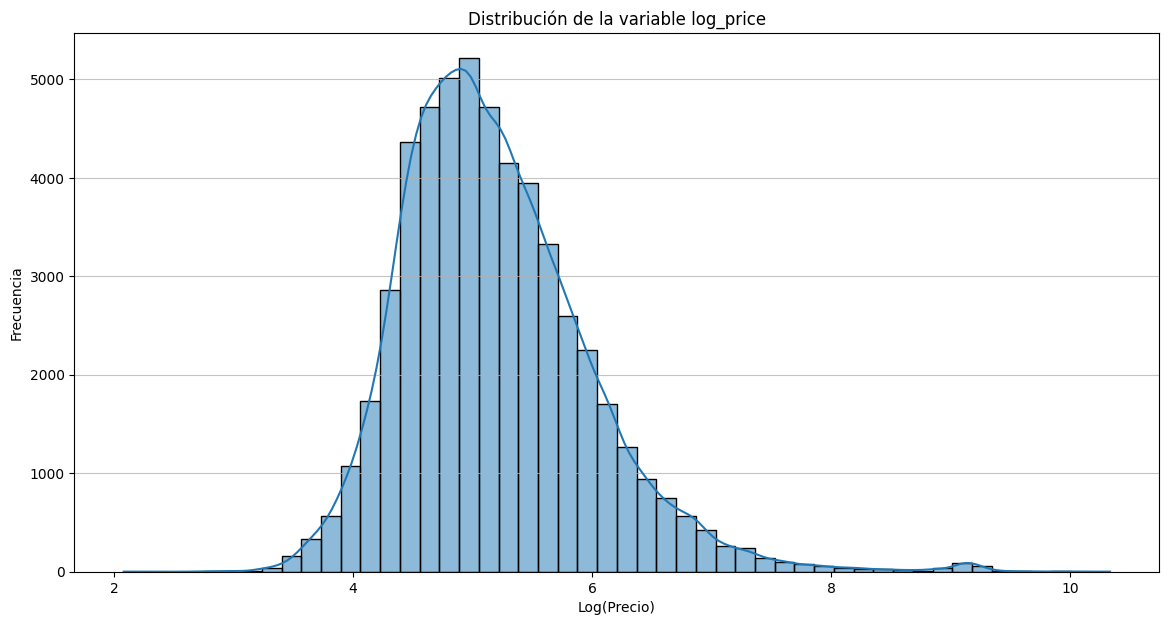

In [14]:
plot.figure(figsize=(14, 7))
sns.histplot(df_limpio['log_price'], bins=50, kde=True)
plot.title('Distribución de la variable log_price')
plot.xlabel('Log(Precio)')
plot.ylabel('Frecuencia')
plot.grid(axis='y', alpha=0.75)
plot.show()

### Estadísticas descriptivas de `log_price`

In [15]:
df_limpio['log_price'].describe()

,log_price
count,53963.000000
mean,5.189191
std,0.789215
min,2.079442
25%,4.644391
50%,5.081404
75%,5.624018
max,10.335724


Esta transformación es beneficiosa ya que ha logrado reducir la asimetría y hacer que la distribución sea mucho más parecida a una distribución normal, lo cual es útil para muchos modelos que son sensibles a la asimetría y a la presencia de outliers.


d) Obtenga estadísticas descriptivas de price según room_type y realice boxplots
paralelos. ¿Qué diferencias encuentra entre los tipos de habitación?


In [16]:
df_limpio.groupby('room_type')['price'].describe()

,count,mean,std,min,25%,50%,75%,max
room_type,,,,,,,,
Entire home/apt,48706.0,289.198743,697.432229,8.0,108.00,165.0,279.00,30814.0
Hotel room,456.0,562.655702,1198.546582,43.0,254.00,353.5,522.75,11500.0
Private room,4667.0,223.264195,503.664420,18.0,70.00,100.0,223.00,11291.0
Shared room,134.0,70.216418,57.890662,16.0,40.25,52.5,71.75,396.0


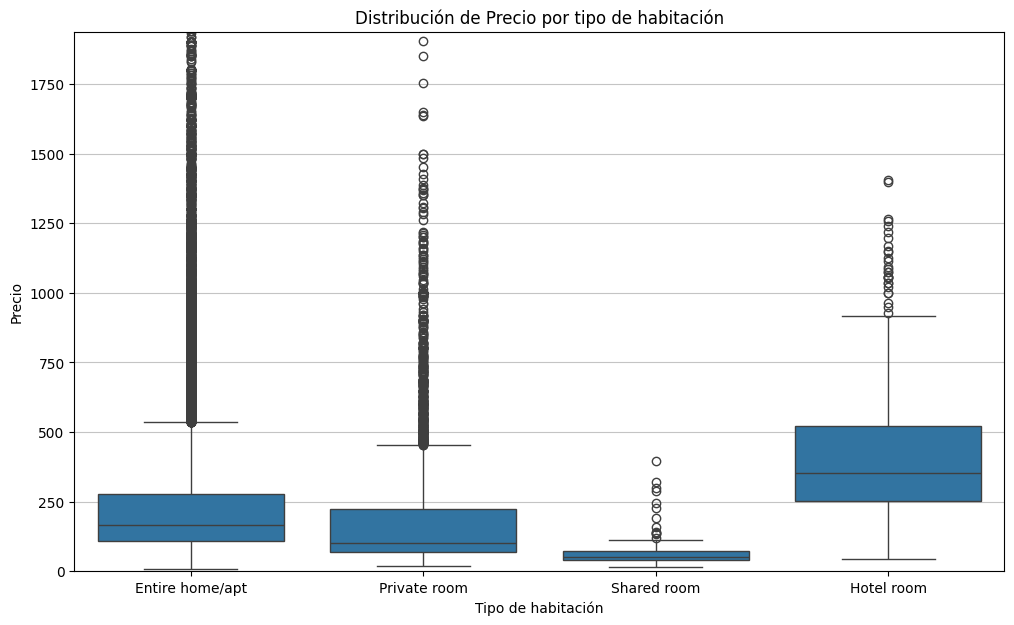

In [17]:
plot.figure(figsize=(12, 7))
sns.boxplot(x='room_type', y='price', data=df_limpio)
plot.title('Distribución de Precio por tipo de habitación')
plot.xlabel('Tipo de habitación')
plot.ylabel('Precio')
plot.ylim(0, df_limpio['price'].quantile(0.99)) #Para mejor visualización reducimos la cantidad de datos capturados en el botplox
plot.grid(axis='y', alpha=0.75)
plot.show()

1. Entire home/apt: Vivienda/apartamento completo

Estadísticas: Con 48,706 observaciones, es el tipo de habitación más frecuente. Tiene un precio promedio de 289.20 con una mediana de 165.00. Los precios varían desde 8.00 hasta 30,814.00, mostrando una gran dispersión (desviación estándar de 697.43) y muchos valores extremos altos. El 75% de las propiedades está por debajo de 279.00.
Segundo boxplot más ancho lo que implica una distribución relativamente alta.

2. Hotel room: Habitación de hotel

Estadísticas: Es el tipo de habitación con el precio promedio más alto, 562.66, y una mediana de 353.50, aunque con solo 456 observaciones. La dispersión también es muy alta (desviación estándar de 1198.55), con precios que van desde 43.00 hasta 11,500.00.
Boxplot mas ancho: La visualización está limitada por el percentil 99 del precio general, pero se puede inferir que tiene una distribución de precios alta.

3. Private room: Habitación privada

Estadísticas: Con 4,667 observaciones, es el segundo tipo más común. Su precio promedio es de 223.26 y la mediana es de 100.00. Los precios oscilan entre 18.00 y 11,291.00, con una desviación estándar de 503.66. También presenta asimetría a la derecha.
Boxplot: La mediana es considerablemente más baja que la de 'Entire home/apt', y la caja es más estrecha, lo que sugiere precios más asequibles y menor variabilidad dentro del rango intercuartílico.

4. Shared room: Habitación compartida

Estadísticas: Es el tipo de habitación menos frecuente (134 observaciones) y el más económico, con un precio promedio de 70.22 y una mediana de 52.50. Los precios varían de 16.00 a 396.00, con la menor desviación estándar (57.89), lo que indica una menor dispersión.
Boxplot: Este tipo de habitación muestra la caja y los bigotes más cortos, y la mediana más baja, lo que confirma que las habitaciones compartidas son consistentemente las más baratas y tienen la menor variabilidad de precios.

###Boxplots paralelos utilizando log_price

In [18]:
df_limpio.groupby('room_type')['log_price'].describe()

,count,mean,std,min,25%,50%,75%,max
room_type,,,,,,,,
Entire home/apt,48706.0,5.216222,0.769881,2.079442,4.682131,5.105945,5.631212,10.335724
Hotel room,456.0,5.926062,0.708497,3.761200,5.537334,5.867882,6.259087,9.350102
Private room,4667.0,4.867242,0.871055,2.890372,4.248495,4.605170,5.407172,9.331761
Shared room,134.0,4.069419,0.540861,2.772589,3.695053,3.960768,4.273170,5.981414


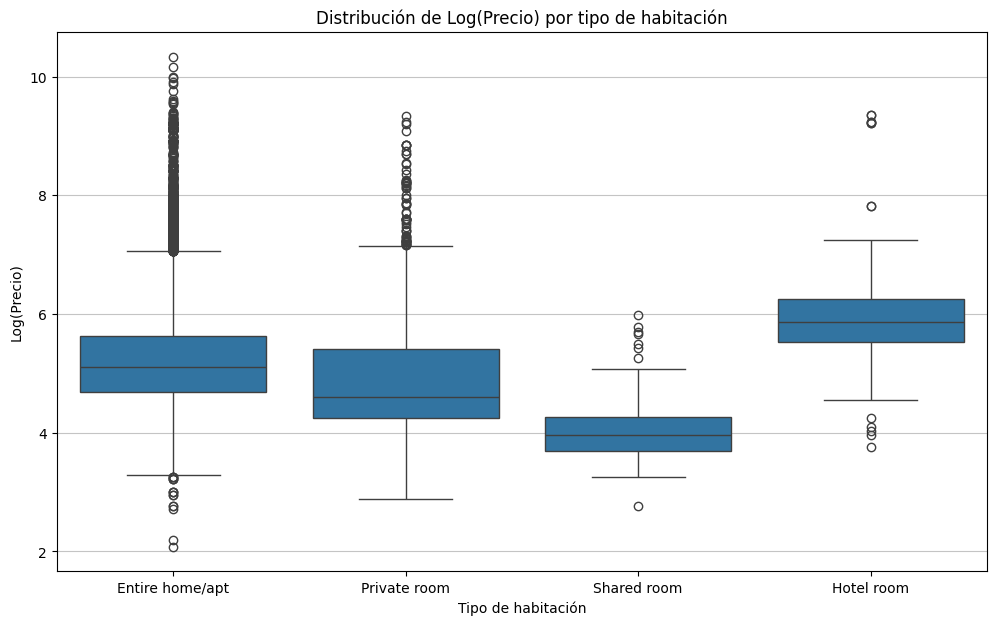

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 7))
sns.boxplot(x='room_type', y='log_price', data=df_limpio)
plt.title('Distribución de Log(Precio) por tipo de habitación')
plt.xlabel('Tipo de habitación')
plt.ylabel('Log(Precio)')
plt.grid(axis='y', alpha=0.75)
plt.show()

Análisis de log_price

Medianas:
En cuanto al valor de medianas, los tipos de habitación mantienen el mismo orden. Siendo la más cara Hotel room (5.87), seguida de Entire home/atp (5.11). Una opción intermedia es Private room con (4.61) y la más barata Shared room (3.96).

La dispersión cambia al utilizar logaritmos:
Private room pasa a tener el boxplot más ancho (mayor IQR), lo que nos muestra mayor variedad de precios ofrecidos para este tipo de alojamiento.
Se puede observar una reducción significativa en la variabilidad de Hotel room, pudiendo decir así que este tipo de habitación y Entire home/atp son considerados como de dispersión media.
Por último Shared room sigue siendo considerado el que posee menor variabilidad en los precios.

Outliers:
Siguen observandose outliers lo cual indica precios muy altos o muy bajos, especialmente en Entire home/apt y private room

Desde ahora en adelante y luego del análisis se trabajará con la variable log_price

e) Obtenga estadísticas descriptivas de price según neighbourhood_cleansed o la
variable de barrio equivalente. Identifique barrios con precios altos y bajos,
teniendo cuidado con barrios que tengan muy pocas observaciones.


In [20]:
barrios_estadisticas = df_limpio.groupby('neighbourhood_cleansed')['log_price'].describe()
barrios_estadisticas.head(10)

,count,mean,std,min,25%,50%,75%,max
neighbourhood_cleansed,,,,,,,,
Batignolles-Monceau,3705.0,5.143316,0.800573,2.079442,4.605170,5.030438,5.545177,9.990903
Bourse,2252.0,5.426497,0.791574,2.197225,4.919981,5.347108,5.837730,9.331761
Buttes-Chaumont,2655.0,4.856890,0.714047,3.178054,4.406719,4.753590,5.164786,10.335724
Buttes-Montmartre,5172.0,4.929253,0.662175,3.044522,4.499810,4.828314,5.274278,9.870964
Entrepôt,3411.0,5.081483,0.687561,2.890372,4.605170,5.010635,5.461709,9.218804
Gobelins,1605.0,4.900736,0.662145,3.258097,4.465908,4.828314,5.252273,9.120744
Hôtel-de-Ville,1891.0,5.392519,0.750314,3.663562,4.897840,5.332719,5.780744,9.903488
Louvre,1445.0,5.620262,0.780693,3.663562,5.105945,5.537334,6.035481,9.372884
Luxembourg,1841.0,5.502046,0.811014,2.772589,4.955827,5.442418,5.976351,9.210240


In [21]:
barrios_estadisticas.shape

(20, 8)

In [22]:
barrios_observaciones = df_limpio['neighbourhood_cleansed'].value_counts().reset_index()
barrios_observaciones.columns = ['neighbourhood_cleansed', 'count']
display(barrios_observaciones.head(5))
display(barrios_observaciones.tail(5))

,neighbourhood_cleansed,count
0,Buttes-Montmartre,5172
1,Popincourt,4379
2,Vaugirard,4162
3,Passy,3909
4,Batignolles-Monceau,3705


,neighbourhood_cleansed,count
15,Panthéon,1867
16,Luxembourg,1841
17,Palais-Bourbon,1632
18,Gobelins,1605
19,Louvre,1445


No observamos barrios con un nivel de observaciones sustancialmente bajo.

### Barrios con `log_price` promedio más alto

In [23]:
barrios_altos = barrios_estadisticas.sort_values(by='mean', ascending=False).head(10)
print("Top 10 barrios con log_price promedio más alto:")
display(barrios_altos)

Top 10 barrios con log_price promedio más alto:


,count,mean,std,min,25%,50%,75%,max
neighbourhood_cleansed,,,,,,,,
Élysée,2149.0,5.699455,0.898395,2.944439,5.075174,5.631212,6.190315,9.754465
Louvre,1445.0,5.620262,0.780693,3.663562,5.105945,5.537334,6.035481,9.372884
Palais-Bourbon,1632.0,5.528566,0.890579,3.332205,4.941642,5.420535,5.971899,9.985528
Luxembourg,1841.0,5.502046,0.811014,2.772589,4.955827,5.442418,5.976351,9.210240
Bourse,2252.0,5.426497,0.791574,2.197225,4.919981,5.347108,5.837730,9.331761
Passy,3909.0,5.422942,0.906971,2.890372,4.820282,5.313206,5.886104,9.581697
Hôtel-de-Ville,1891.0,5.392519,0.750314,3.663562,4.897840,5.332719,5.780744,9.903488
Temple,2662.0,5.378179,0.705225,3.496508,4.905275,5.344721,5.771441,9.210240
Opéra,2775.0,5.339270,0.747753,2.708050,4.836282,5.288267,5.763621,10.161033


In [24]:
barrios_bajos = barrios_estadisticas.sort_values(by='mean', ascending=True).head(10)
print("Top 10 barrios con log_price promedio más bajo:")
display(barrios_bajos)

Top 10 barrios con log_price promedio más bajo:


,count,mean,std,min,25%,50%,75%,max
neighbourhood_cleansed,,,,,,,,
Ménilmontant,2512.0,4.793962,0.621463,2.995732,4.394449,4.682131,5.075174,9.210240
Buttes-Chaumont,2655.0,4.856890,0.714047,3.178054,4.406719,4.753590,5.164786,10.335724
Gobelins,1605.0,4.900736,0.662145,3.258097,4.465908,4.828314,5.252273,9.120744
Buttes-Montmartre,5172.0,4.929253,0.662175,3.044522,4.499810,4.828314,5.274278,9.870964
Reuilly,2035.0,4.981329,0.746204,3.258097,4.488636,4.867534,5.332719,9.570529
Observatoire,1904.0,5.016334,0.725090,2.772589,4.521789,4.905275,5.399291,9.210340
Popincourt,4379.0,5.029048,0.653910,2.995732,4.595120,4.941642,5.382196,9.615805
Entrepôt,3411.0,5.081483,0.687561,2.890372,4.605170,5.010635,5.461709,9.218804
Batignolles-Monceau,3705.0,5.143316,0.800573,2.079442,4.605170,5.030438,5.545177,9.990903


Utilizamos el precio promedio para clasificar a los barrios en las categorías precio bajo y alto. De esta manera podemos ver que los barrios de precios promedio más alto son Élysée y Louvre y los de precios promedio más bajo Ménilmontant y Buttes-Chaumont. A simple vista destacar que el desvío de los barrios con precios más elevados es mayor que el de los más bajos en su mayoría.

f) Realice un scatterplot entre price y alguna variable de tamaño o capacidad
disponible, por ejemplo bedrooms, beds, bathrooms o accommodates. Comente
los resultados.


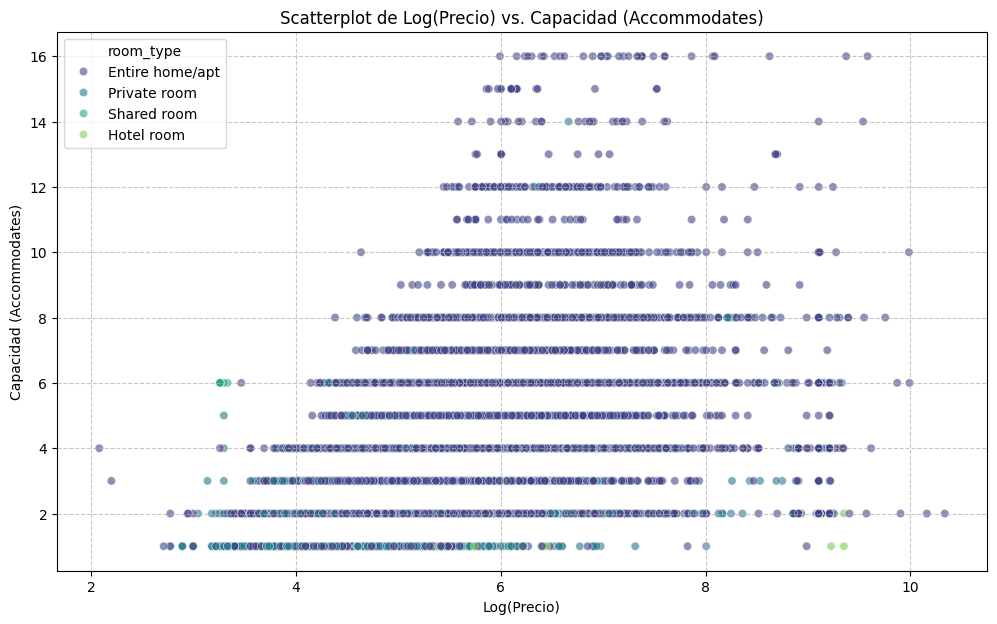

In [25]:
plt.figure(figsize=(12, 7))
sns.scatterplot(x='log_price', y='accommodates', data=df_limpio, alpha=0.6, hue='room_type', palette='viridis')
plt.title('Scatterplot de Log(Precio) vs. Capacidad (Accommodates)')
plt.xlabel('Log(Precio)')
plt.ylabel('Capacidad (Accommodates)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### Análisis del Scatterplot de `log_price` vs. `accommodates`
Este scatterplot visualiza la relación entre log_price y accomodates.

Relación positiva:
Se observa una tendencia general a que a mayor capacidad, mayor es el precio.

Variabilidad:
Hay una considerable dispersión en los puntos, por lo que, si bien hay una correlación positiva, hay otros factores además de "accomodates" que influyen en el precio.

Densidad:
La mayoría de las propiedades se encuentran dentro de las capacidades más bajas. Esto suele ser muy común en ciudades como París

g) Construya una matriz de correlaciones para variables numéricas relevantes.
Puede considerar price, accommodates, bedrooms, beds, bathrooms,
minimum_nights, maximum_nights, number_of_reviews, review_scores_rating y
availability_365. Ignore identificadores, coordenadas y variables que no aporten
una interpretación directa.


In [26]:
var_num_relevantes = ['log_price', 'accommodates', 'bedrooms', 'beds', 'bathrooms', 'minimum_nights', 'maximum_nights', 'number_of_reviews', 'review_scores_rating', 'availability_365']

df_num_relevantes = df_limpio[var_num_relevantes]
df_num_relevantes.head()

,log_price,accommodates,bedrooms,beds,bathrooms,minimum_nights,maximum_nights,number_of_reviews,review_scores_rating,availability_365
0,4.905275,2,1.0,1.0,1.0,2,30,7,5.00,355
1,4.736198,2,0.0,1.0,1.0,1,730,452,4.62,69
2,5.003946,4,2.0,1.0,1.0,10,130,380,4.73,197
4,4.317488,1,1.0,1.0,1.0,180,360,0,NaN,358
5,3.912023,1,1.0,1.0,1.0,5,1125,63,4.63,82


In [27]:
matriz_corr = df_num_relevantes.corr()

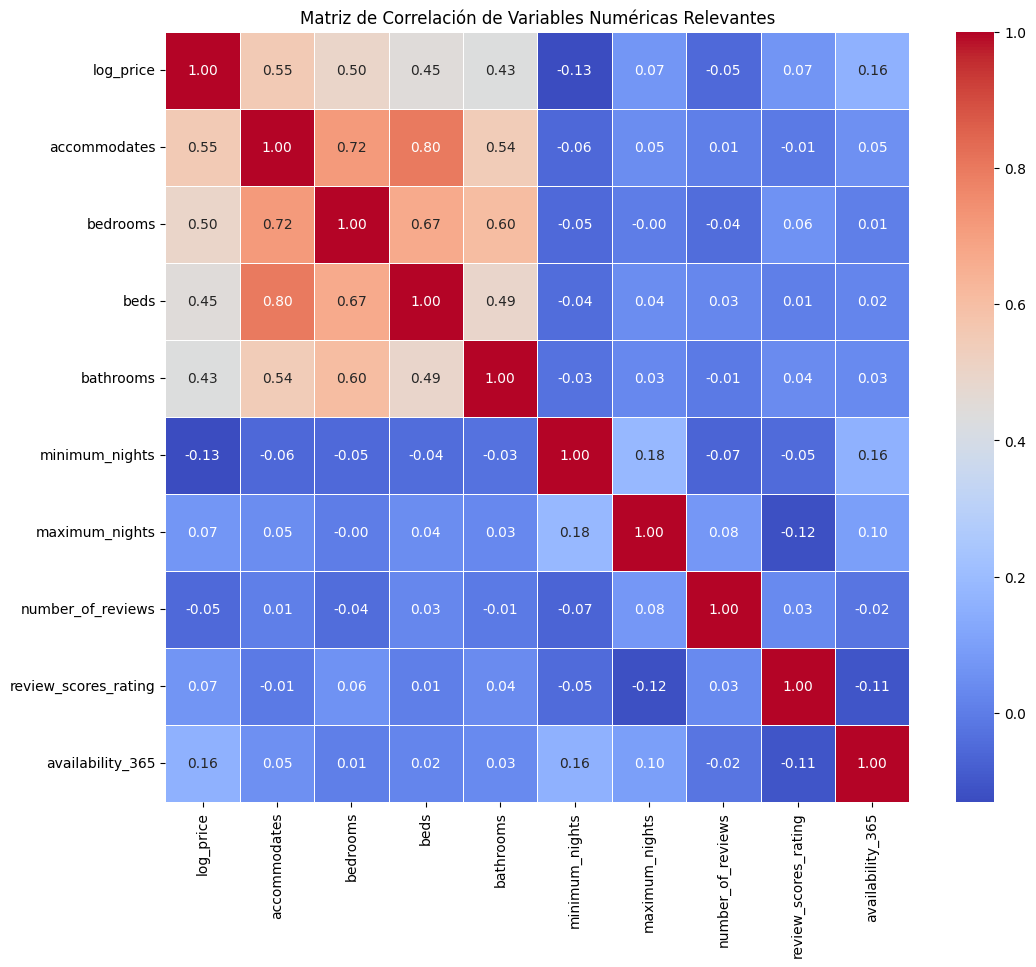

In [28]:
plt.figure(figsize=(12, 10))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Matriz de Correlación de Variables Numéricas Relevantes')
plt.show()

i) ¿Cómo se correlaciona la variable objetivo price con el resto de las variables
numéricas? Comente los principales resultados.

### Análisis de la Matriz de Correlaciones

Observaciones principales:

•Log_price y Capacidad (accomodates, bedrooms, beds y bathrooms):
Se observa una correlación positiva del precio entre moderada y fuerte respecto a la capacidad de las propiedades. Esto indica que las más grandes o con mayor capacidad tienden a tener precios más elevados.

availability_365:
Podría tener una correlación baja o moderada con el precio. Mayor disponibilidad podría indicar una propiedad más cara.

•review_score_rating;
Esta variable muestra las calificaciones de distintos usuarios respecto a las propiedades. Por lo que puede llegar a correlacionarse con el precio positivamente. Aunque la relación es baja.

•number_of_reviews:
Tiene una correlación bastante baja, pero puede indicar que la popularidad dentro de las propiedades correlaciona con el precio de manera positiva.

•minimum_nights y maximum_nights:
Estas variables podrían mostrar correlación positiva y negativa con el precio respectivamente. Se podría inferir que a menor cantidad de días de estadía el precio del alquiler aumenta y viceversa.

h) Analice la cantidad de datos faltantes por variable. Elija qué variables conservará
para el modelado y explique cómo tratará sus valores faltantes.


In [29]:
datos_faltantes = df_limpio.isnull().sum()
datos_faltantes_porcentaje = (datos_faltantes / len(df_limpio)) * 100
informacion_faltante= pd.DataFrame({
    'Datos Faltantes': datos_faltantes,
    'Porcentaje de datos faltantes': datos_faltantes_porcentaje
    })
informacion_faltante = informacion_faltante[informacion_faltante['Datos Faltantes'] > 0].sort_values(by='Porcentaje de datos faltantes', ascending=False)

display(informacion_faltante)

,Datos Faltantes,Porcentaje de datos faltantes
host_neighbourhood,39102,72.460760
host_about,28462,52.743547
neighborhood_overview,27606,51.157274
neighbourhood,27606,51.157274
host_location,11953,22.150362
review_scores_checkin,11662,21.611104
review_scores_value,11661,21.609251
review_scores_location,11661,21.609251
review_scores_communication,11659,21.605545
review_scores_accuracy,11659,21.605545


### Análisis de Datos Faltantes y Estrategia de Tratamiento

Variables con datos faltantes mayores al 50%:

Son todas variables relacionadas al barrio. Dado que el csv nos brinda mediante neighbordhood_cleansed los datos correspondientes y fundamentales para el anális, decimos eliminar el resto de variables relacionadas a los barrios que son las que superan el 50% de datos faltantes.

Variables con datos faltantes mayores al 20%:

Estas son todas variables relacionadas a las review de los alojamientos. Como vimos en la matriz de correlaciones, pueden indicar una correlación positiva pero es poco significativa, por lo que también serán eliminadas. Además nos quedamos con la variable numbers_of_reviews que posee más significatividad.

Variables con datos faltantes mayores al 10%:

La mayoría son variables que corresponden al tiempo y ratio de respuesta del dueño de la propiedad. Se puede pensar que no generarán un gran cambio respecto al precio de las mismas y por eso serán eliminadas.

Variables con datos faltantes menor al 10%:

Dentro de ellas se encuentran varias relacionadas al host, su identidad, foto, nombre, etc. No creemos que sean de gran importancia para el análisis por lo que serán eliminadas.
Variables relacionadas con la capacidad, como beds, bathrooms y bedrooms si serán tratadas dado que vimos la que correlacionan con los precios de manera significativa, bathroom_text nos parece redundante así que será eliminada.
La variable has_availability también será tratada dado que puede inferir como vimos con la variable availability_365

In [30]:
columnas_a_eliminar = informacion_faltante[informacion_faltante['Porcentaje de datos faltantes'] > 10].index.tolist()

print(f"Columnas a eliminar por tener más del 10% de datos faltantes: {columnas_a_eliminar}")
df_limpio = df_limpio.drop(columns=columnas_a_eliminar)

print(f"Nueva forma del DataFrame después de eliminar columnas: {df_limpio.shape}")

Columnas a eliminar por tener más del 10% de datos faltantes: ['host_neighbourhood', 'host_about', 'neighborhood_overview', 'neighbourhood', 'host_location', 'review_scores_checkin', 'review_scores_value', 'review_scores_location', 'review_scores_communication', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_rating', 'first_review', 'reviews_per_month', 'last_review', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'license']
Nueva forma del DataFrame después de eliminar columnas: (53963, 59)


In [31]:
columnas_a_eliminar_adicionales = [
    'description',
    'host_is_superhost',
    'bathrooms_text',
    'host_identity_verified',
    'host_name',
    'host_picture_url',
    'host_has_profile_pic',
    'host_verifications',
    'host_total_listings_count',
    'host_since',
    'host_listings_count',
    'host_thumbnail_url',
    'picture_url'
]
columnas_a_eliminar_adicionales_existentes = [col for col in columnas_a_eliminar_adicionales if col in df_limpio.columns]

print(f"Columnas adicionales a eliminar: {columnas_a_eliminar_adicionales_existentes}")
df_limpio = df_limpio.drop(columns=columnas_a_eliminar_adicionales_existentes)

print(f"Nueva forma del DataFrame después de eliminar columnas adicionales: {df_limpio.shape}")

Columnas adicionales a eliminar: ['description', 'host_is_superhost', 'bathrooms_text', 'host_identity_verified', 'host_name', 'host_picture_url', 'host_has_profile_pic', 'host_verifications', 'host_total_listings_count', 'host_since', 'host_listings_count', 'host_thumbnail_url', 'picture_url']
Nueva forma del DataFrame después de eliminar columnas adicionales: (53963, 46)


In [32]:
mediana_beds = df_limpio['beds'].median()
mediana_bedrooms = df_limpio['bedrooms'].median()
mediana_bathrooms = df_limpio['bathrooms'].median()

df_limpio['beds'].fillna(mediana_beds, inplace=True)
df_limpio['bedrooms'].fillna(mediana_bedrooms, inplace=True)
df_limpio['bathrooms'].fillna(mediana_bathrooms, inplace=True)

moda_has_availability = df_limpio['has_availability'].mode()[0]
df_limpio['has_availability'].fillna(moda_has_availability, inplace=True)

print("Valores faltantes después de la imputación para las columnas seleccionadas:")
variables_modificadas = ['beds', 'bathrooms', 'bedrooms', 'has_availability']
ver_faltantes = df_limpio[variables_modificadas].isnull().sum()
display(ver_faltantes)

Valores faltantes después de la imputación para las columnas seleccionadas:


/tmp/ipykernel_762/3565598813.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_limpio['beds'].fillna(mediana_beds, inplace=True)
/tmp/ipykernel_762/3565598813.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', tr

,0
beds,0
bathrooms,0
bedrooms,0
has_availability,0


### Justificación y Tratamiento de Variables con Datos Faltantes
Numéricas: beds, bathrooms y bedrooms

Se reemplazan los datos faltantes por la mediana para mantener robustez y preservar la distribución central de la variable

Categórica: has_availability

Se reemplazó por la moda, asumiendo el valor más frecuente y por ende el más representativo.

###3) Tratamiento de outliers y limpieza


a) Analice la presencia de outliers en la variable price.


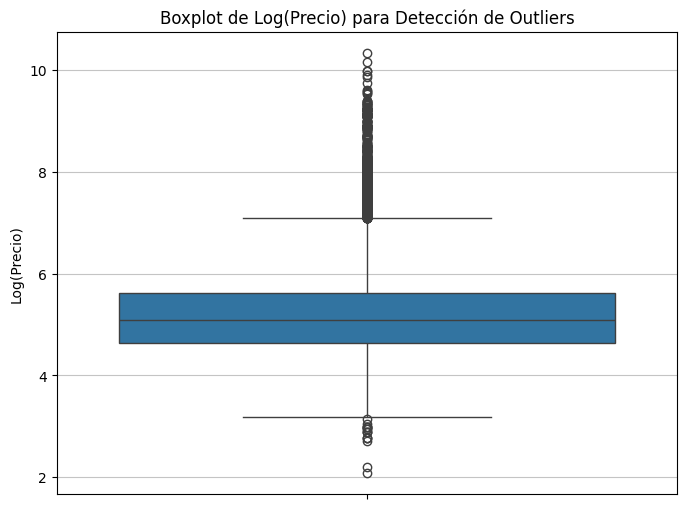

In [33]:
plt.figure(figsize=(8, 6))
sns.boxplot(y=df_limpio['log_price'])
plt.title('Boxplot de Log(Precio) para Detección de Outliers')
plt.ylabel('Log(Precio)')
plt.grid(axis='y', alpha=0.75)
plt.show()

### Análisis de Outliers en log_price mediante Boxplot

Observacioens

Los puntos por fuera de los bigotes son outliers.

A pesar de la transformación logarítmica, todavía observamos outliers tanto en la parte inferior como en la superior de la distribución. Esto indica que existen propiedades con precios logarítmicos excepcionalmente bajos o altos en comparación con la mayoría.

La presencia de outliers puede deberse a propiedades de lujo extremo, propiedades con características muy atípicas, o incluso errores en la entrada de datos.

b) Analice posibles outliers en otras variables relevantes, como accommodates,
bedrooms, beds, bathrooms, minimum_nights, availability_365 y
number_of_reviews.


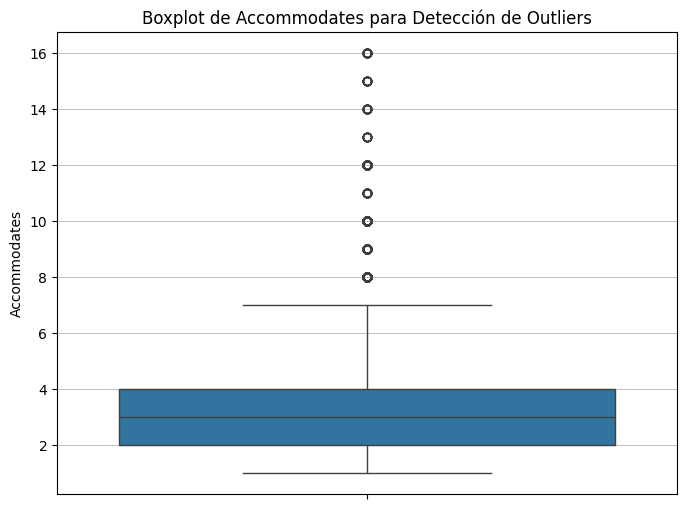

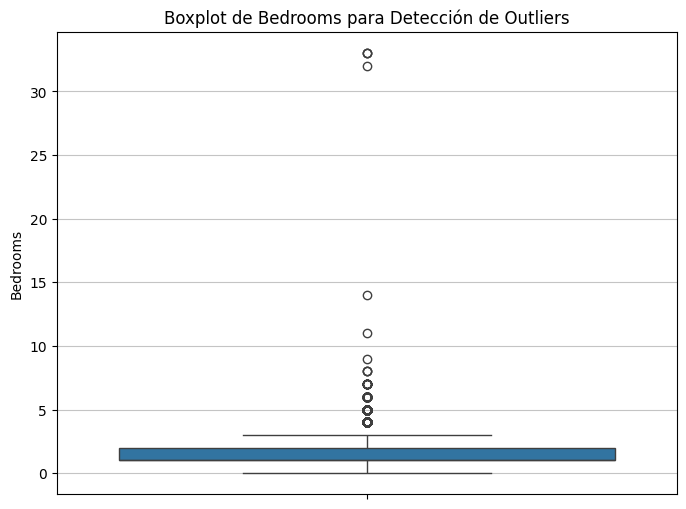

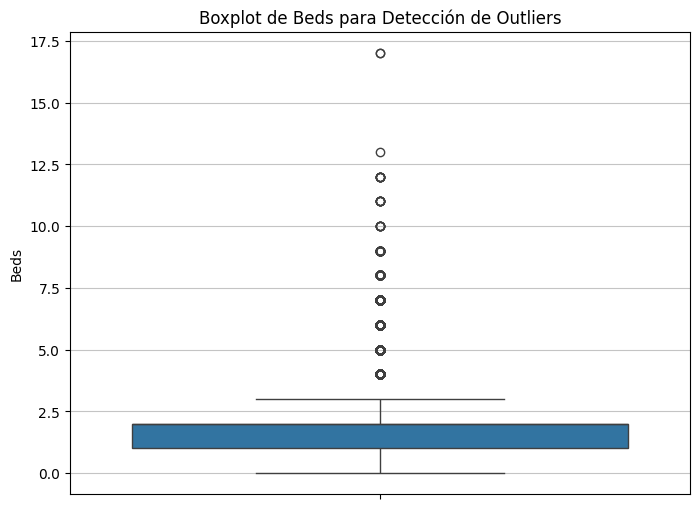

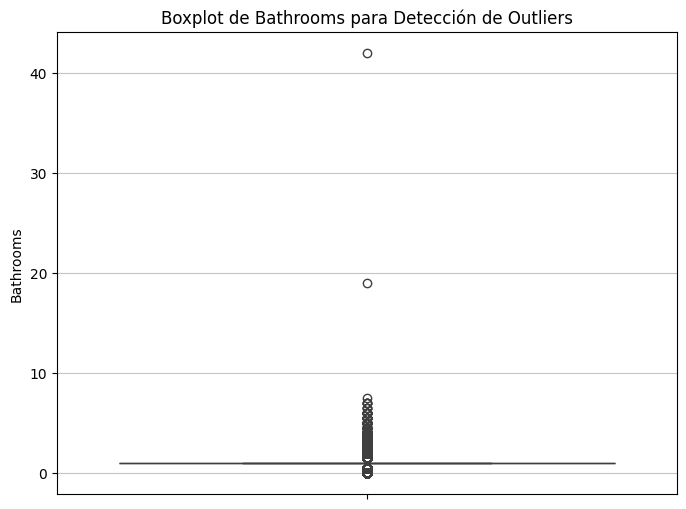

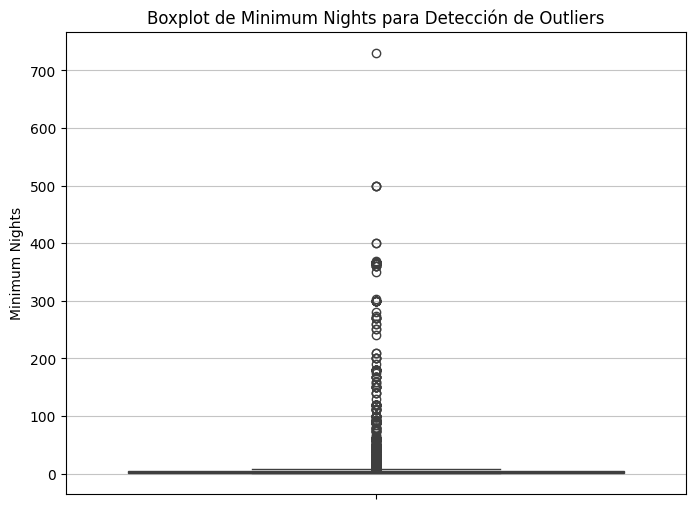

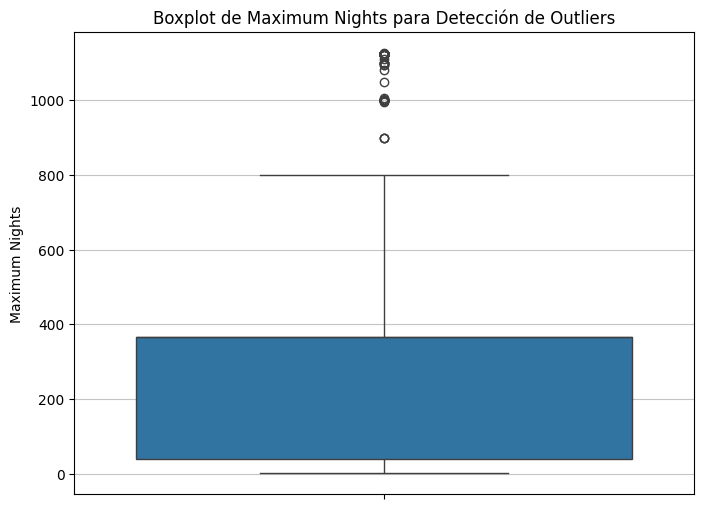

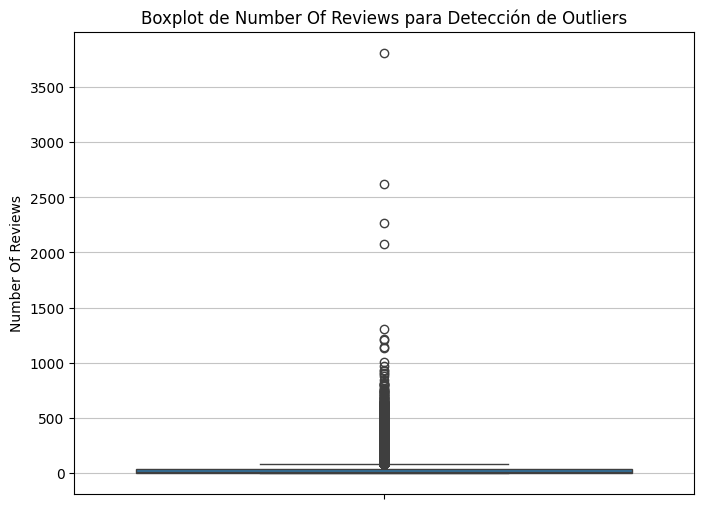

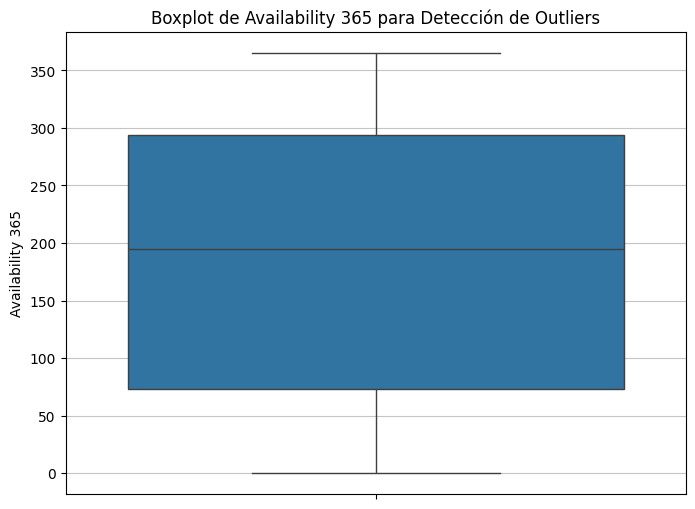

In [34]:

var_num_relevantes = ['accommodates', 'bedrooms', 'beds', 'bathrooms', 'minimum_nights', 'maximum_nights', 'number_of_reviews', 'availability_365'] #la redefinimos sin 'review_scores_rating' dado que fue eliminado

for var in var_num_relevantes:
    plt.figure(figsize=(8, 6))
    sns.boxplot(y=df_limpio[var])
    plt.title(f'Boxplot de {var.replace('_', ' ').title()} para Detección de Outliers')
    plt.ylabel(var.replace('_', ' ').title())
    plt.grid(axis='y', alpha=0.75)
    plt.show()

Las variables con pocos/ningún outliers son:

Bedrooms, accomodates, beds, y availability. De ellos eliminaremos outliers de bedroom que muestran más de 30 habitaciones. El resto parecen datos posibles dado la cantidad de muestras observadas y la poca cantidad de los mismos.

Las variables con muchos outliers son:
Bathrooms, minimum_nights, maximum_nights y number_of_reviews. También recibirán tratamiento

c) Elimine o trate los outliers que considere problemáticos. Deberá fundamentar el
criterio utilizado. Puede utilizar percentiles, rango intercuartílico, reglas basadas
en conocimiento del problema o inspección gráfica.


Para el tratamiento de outliers, utilizaremos una combinación de eliminación y capping basada en percentiles, según la naturaleza y distribución de cada variable.

El análisis visual de bedrooms sugiere que existen unos pocos valores extremadamente altos (más de 30 habitaciones) que son poco realistas para alojamientos estándar y podrían ser errores de entrada de datos. Eliminaremos estas filas directamente, ya que son pocas y distorsionan significativamente la distribución.

In [35]:
print(f"Filas antes de eliminar outliers de 'bedrooms': {df_limpio.shape[0]}")

df_limpio = df_limpio[df_limpio['bedrooms'] <= 30]

print(f"Filas después de eliminar outliers de 'bedrooms': {df_limpio.shape[0]}")

Filas antes de eliminar outliers de 'bedrooms': 53963
Filas después de eliminar outliers de 'bedrooms': 53959


Outliers en minimum_nights, maximum_nights, number_of_reviews (Método IQR)

Para estas variables, aplicaremos el método del Rango Intercuartílico para identificar y tratar los outliers. Los valores que caen por debajo de Q1 - 1.5 * IQR o por encima de Q3 + 1.5 * IQR serán cappeados a esos respectivos límites. Este enfoque es robusto y permite mantener las observaciones, ajustando solo los valores extremos.

Aplicando tratamiento de outliers (IQR) a las siguientes variables:
  - 'minimum_nights': valores limitados entre -2.50 y 9.50
  - 'maximum_nights': valores limitados entre -447.50 y 852.50
  - 'number_of_reviews': valores limitados entre -47.00 y 81.00

Forma del DataFrame después del tratamiento de outliers: (53959, 46)


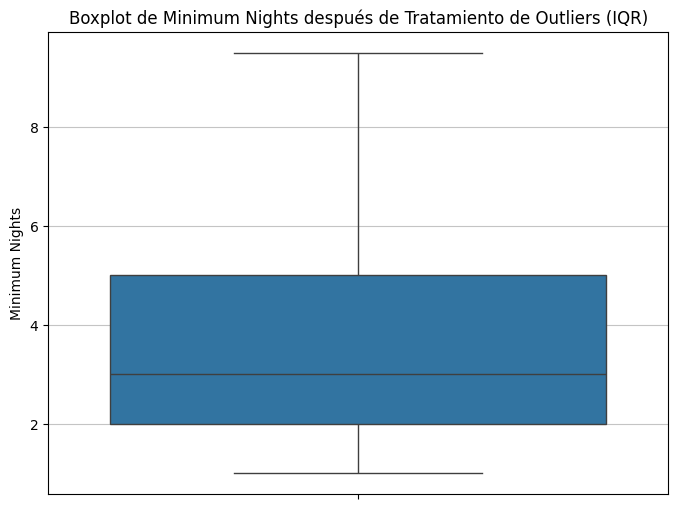

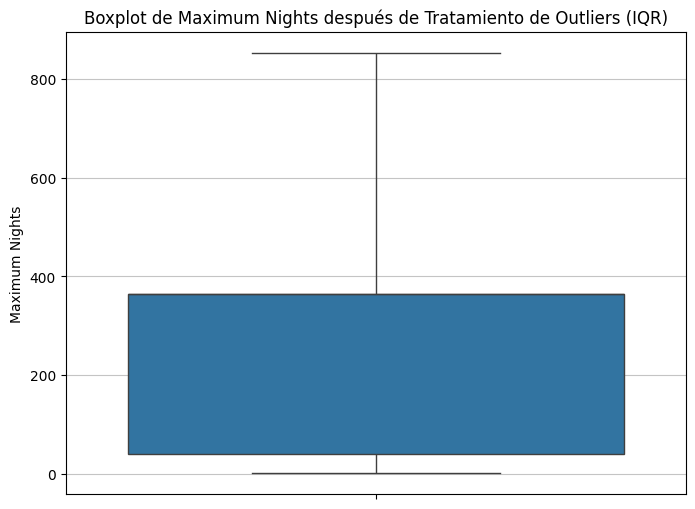

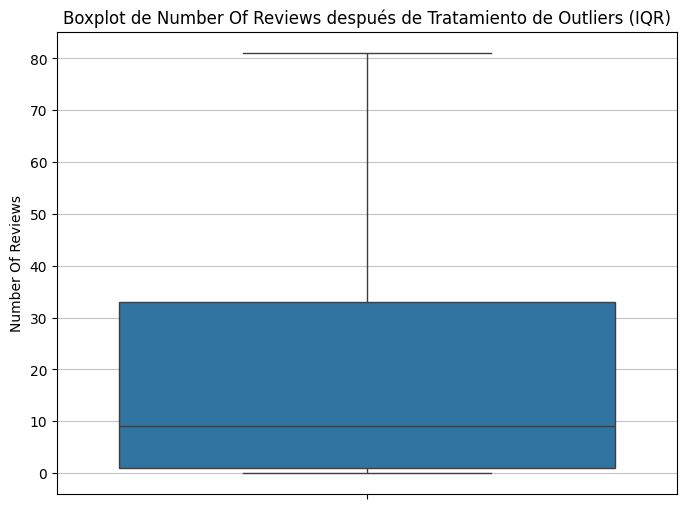

In [36]:
variables_con_muchos_outliers = ['minimum_nights', 'maximum_nights', 'number_of_reviews']

print("Aplicando tratamiento de outliers (IQR) a las siguientes variables:")
for var_name in variables_con_muchos_outliers:
    Q1 = df_limpio[var_name].quantile(0.25)
    Q3 = df_limpio[var_name].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df_limpio[var_name] = np.where(df_limpio[var_name] < lower_bound, lower_bound, df_limpio[var_name])
    df_limpio[var_name] = np.where(df_limpio[var_name] > upper_bound, upper_bound, df_limpio[var_name])

    print(f"  - '{var_name}': valores limitados entre {lower_bound:.2f} y {upper_bound:.2f}")

print(f"\nForma del DataFrame después del tratamiento de outliers: {df_limpio.shape}")

for var_name in variables_con_muchos_outliers:
    plt.figure(figsize=(8, 6))
    sns.boxplot(y=df_limpio[var_name])
    plt.title(f'Boxplot de {var_name.replace('_', ' ').title()} después de Tratamiento de Outliers (IQR)')
    plt.ylabel(var_name.replace('_', ' ').title())
    plt.grid(axis='y', alpha=0.75)
    plt.show()

Tratamiento para la variable bathroom:

Dado que el método IQR resulta en un 'capping' muy restrictivo para la variable bathrooms optaremos por un enfoque diferente. Utilizaremos el percentil 99 como límite superior para los valores de bathrooms. Esto nos permitirá mantener una mayor variabilidad para los valores altos que son realistas, mientras que los valores excesivamente extremos serán ajustados.

Estadísticas descriptivas de 'bathrooms' antes del tratamiento de outliers:


,bathrooms
count,53959.000000
mean,1.212050
std,0.528344
min,0.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,19.000000



El percentil 99 para 'bathrooms' es: 3.00

Forma del DataFrame después del tratamiento de outliers de 'bathrooms': (53959, 46)


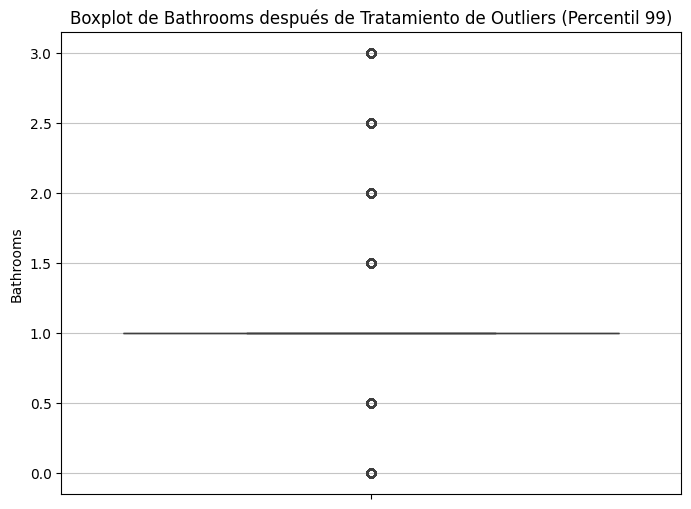

In [37]:
print("Estadísticas descriptivas de 'bathrooms' antes del tratamiento de outliers:")
display(df_limpio['bathrooms'].describe())

p99_bathrooms = df_limpio['bathrooms'].quantile(0.99)
print(f"\nEl percentil 99 para 'bathrooms' es: {p99_bathrooms:.2f}")

df_limpio['bathrooms'] = np.where(df_limpio['bathrooms'] > p99_bathrooms, p99_bathrooms, df_limpio['bathrooms'])

print(f"\nForma del DataFrame después del tratamiento de outliers de 'bathrooms': {df_limpio.shape}")

plt.figure(figsize=(8, 6))
sns.boxplot(y=df_limpio['bathrooms'])
plt.title(f'Boxplot de Bathrooms después de Tratamiento de Outliers (Percentil 99)')
plt.ylabel('Bathrooms')
plt.grid(axis='y', alpha=0.75)
plt.show()

Como se mencionó anteriormente, el percentil 99 para bathrooms fue de 3.00. Esto significa que antes del tratamiento, aproximadamente el 1% de las propiedades (unas 540 de las 53959) tenían más de 3 baños. Tras aplicar el 'capping' al percentil 99, todos esos valores fueron ajustados a 3.00.

d) Luego de la limpieza, vuelva a graficar la distribución de price y compare con la
distribución original.


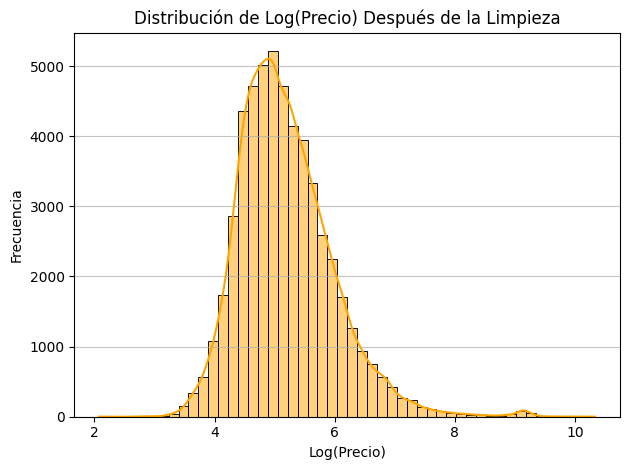


Estadísticas Descriptivas de Log(Precio) Después de la Limpieza:


,log_price
count,53959.000000
mean,5.189209
std,0.789229
min,2.079442
25%,4.644391
50%,5.081404
75%,5.624018
max,10.335724


In [38]:

sns.histplot(df_limpio['log_price'], bins=50, kde=True, color='orange')
plt.title('Distribución de Log(Precio) Después de la Limpieza')
plt.xlabel('Log(Precio)')
plt.ylabel('Frecuencia')
plt.grid(axis='y', alpha=0.75)

plt.tight_layout()
plt.show()

print("\nEstadísticas Descriptivas de Log(Precio) Después de la Limpieza:")
display(df_limpio['log_price'].describe())

Tras la limpieza de datos, las estadísticas descriptivas de la variable objetivo se mantuvieron bastante similares a las originales, ya que se priorizó la conservación de los registros atípicos mediante técnicas de capping en la mayoría de los casos. De esta forma, se buscó reducir la influencia de los valores extremos sin perder información relevante, favoreciendo la robustez del análisis.

e) Vuelva a calcular la matriz de correlaciones. ¿Observa cambios relevantes luego
de la limpieza?

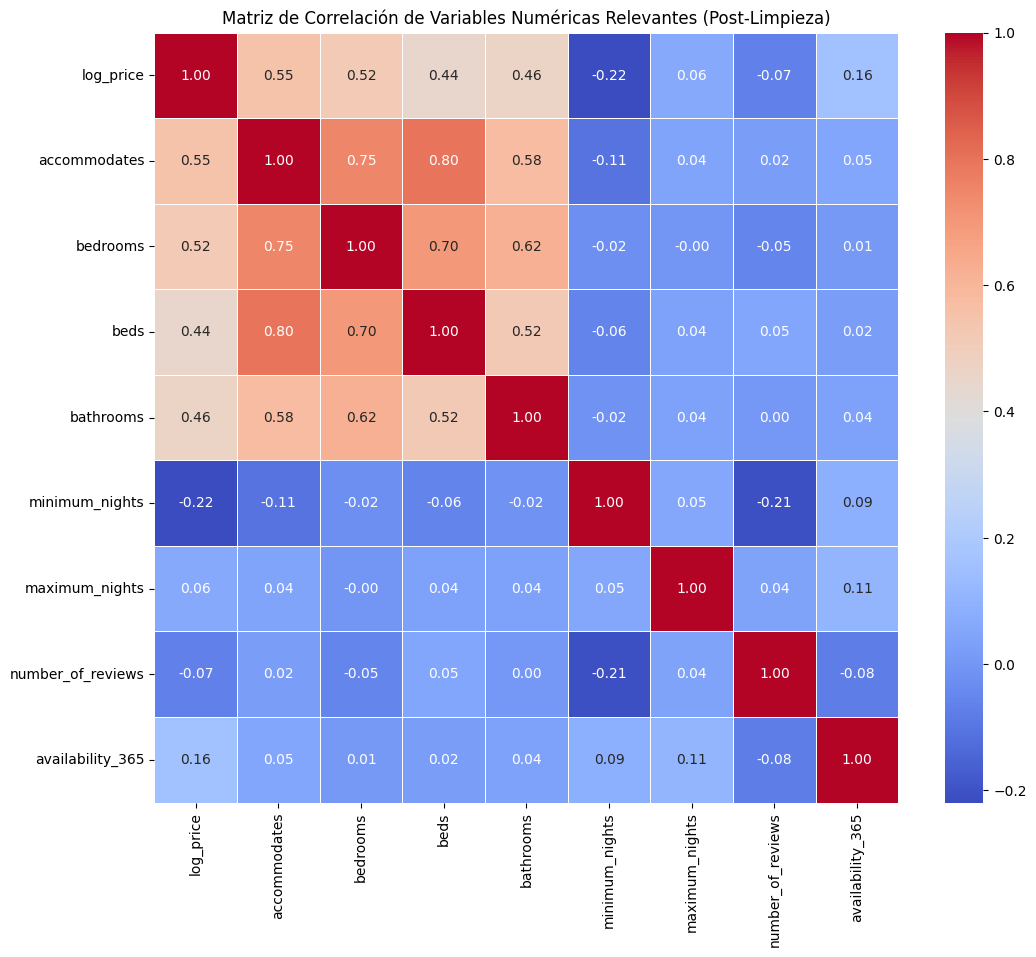

In [39]:
var_num_relevantes_post_limpieza = [
    'log_price', 'accommodates', 'bedrooms', 'beds', 'bathrooms',
    'minimum_nights', 'maximum_nights', 'number_of_reviews', 'availability_365'
]

var_num_relevantes_post_limpieza_existentes = [
    col for col in var_num_relevantes_post_limpieza if col in df_limpio.columns
]

df_num_relevantes_post_limpieza = df_limpio[var_num_relevantes_post_limpieza_existentes]

matriz_corr_post_limpieza = df_num_relevantes_post_limpieza.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(matriz_corr_post_limpieza, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Matriz de Correlación de Variables Numéricas Relevantes (Post-Limpieza)')
plt.show()

Comparación de las Matrices de Correlación (Antes vs. Después de la Limpieza):

Correlación con log_price:

bedrooms: La correlación de log_price con bedrooms ha aumentado de 0.5 a 0.52. Esto sugiere que al eliminar los valores atípicos extremos en bedrooms (aquellos mayores a 30), la relación lineal entre el número de dormitorios y el precio logarítmico se ha vuelto un poco más fuerte y definida.

bathrooms: Similarmente, la correlación de log_price con bathrooms ha subido de 0.43 a 0.46. El tratamiento de outliers en bathrooms (limitando al percentil 99) ha permitido que esta variable tenga una relación más clara con el precio.

number_of_reviews: Esta variable mostró un cambio interesante. Su correlación con log_price pasó de -0.05 a -0.07. Aunque sigue siendo una correlación débil, la magnitud de la relación negativa ha aumentado. Esto, siendo solo una mera interpretación, se puede ver como que a menor precio de la propiedad, mayor es la concurrencia y por ende mayor la cantidad de reviews que obtiene.

minimum_nights: Esta es la que más cambio luego del tratamiento. Al eliminar los outliers se pronunció una mayor correlación negativa con el log_price, pasando de -0,13 a -0,22.

Las correlaciones de log_price con accommodates, beds, maximum_nights y availability_365 se mantuvieron con cambios muy poco significativos, lo que indica que estas relaciones ya eran bastante robustas o que el tratamiento de outliers no las afectó significativamente.



Correlaciones entre Variables Predictoras:

accommodates y bedrooms: La correlación entre estas dos variables ha aumentado de 0.72 a 0.75. Es lógico, ya que a medida que se eliminaron datos atípicos de bedrooms (valores irrealmente altos), la coherencia entre la capacidad y el número de dormitorios se ha reforzado.

beds y bedrooms: También se observa un aumento en la correlación, de 0.67 a 0.70, lo que nuevamente refuerza la relación esperada entre estas variables después de la limpieza.

accommodates y bathrooms: Esta correlación también se ha fortalecido, pasando de 0.54 a 0.58.


Conclusión General:

La limpieza de datos y el tratamiento de outliers han mejorado la coherencia y la fuerza de algunas correlaciones importantes. Las relaciones entre la variable objetivo log_price y variables clave como bedrooms, bathrooms y minimum_nights se han fortalecido. Además, las relaciones entre algunas variables predictoras (accommodates, bedrooms, beds, bathrooms) también se han vuelto más lógicas y robustas, lo que sugiere un conjunto de datos más limpio y adecuado para futuras etapas de análisis o modelado. La eliminación de review_scores_rating (debido a su alta cantidad de datos faltantes) también simplifica la matriz, enfocándose en variables más completas y confiables.

###4) Partición del conjunto de datos

a) Defina el conjunto de variables explicativas que utilizará en los modelos.

In [40]:
df_limpio.info()

<class 'pandas.core.frame.DataFrame'>
Index: 53959 entries, 0 to 84054
Data columns (total 46 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            53959 non-null  int64  
 1   listing_url                                   53959 non-null  object 
 2   scrape_id                                     53959 non-null  int64  
 3   last_scraped                                  53959 non-null  object 
 4   source                                        53959 non-null  object 
 5   name                                          53959 non-null  object 
 6   host_id                                       53959 non-null  int64  
 7   host_url                                      53959 non-null  object 
 8   neighbourhood_cleansed                        53959 non-null  object 
 9   latitude                                      53959 non-null  floa

In [41]:
df_limpio["has_availability"].value_counts()

,count
has_availability,
t,53958
f,1


In [45]:
columnas_excluidas = [
    "id", "listing_url", "scrape_id", "last_scraped", "source", "name",
    "host_id", "host_url", "amenities", "minimum_minimum_nights",
    "maximum_minimum_nights", "minimum_maximum_nights", "maximum_maximum_nights",
    "minimum_nights_avg_ntm", "maximum_nights_avg_ntm", "availability_30",
    "availability_60", "availability_90", "calendar_last_scraped", "number_of_reviews_ltm",
    "number_of_reviews_l30d", "availability_eoy", "number_of_reviews_ly", "calculated_host_listings_count_entire_homes", "calculated_host_listings_count_private_rooms",
    "calculated_host_listings_count_shared_rooms", "estimated_revenue_l365d", "has_availability"]
df_limpio1 = df_limpio.drop(columns=columnas_excluidas)

Las variables que se exluyeron, además de las que registraban metadatos o los que contenian textos largos, fueron las que eran redundantes. Pero en particular, se excluyeron "estimated_revenue_l365d" ya que contiene al precio dentro de su cálculo, por lo que afectaria gravemente a la validez externa del modelo al ocurrir una fuga de datos; y "has_availability" al tener una solo valor FALSE en toda la muestra.

b) Separe las variables predictoras de la variable objetivo

In [46]:
x = df_limpio1.drop(columns=["log_price" , "price"])
y = df_limpio1["log_price"]

In [47]:
x.info()

<class 'pandas.core.frame.DataFrame'>
Index: 53959 entries, 0 to 84054
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   neighbourhood_cleansed          53959 non-null  object 
 1   latitude                        53959 non-null  float64
 2   longitude                       53959 non-null  float64
 3   property_type                   53959 non-null  object 
 4   room_type                       53959 non-null  object 
 5   accommodates                    53959 non-null  int64  
 6   bathrooms                       53959 non-null  float64
 7   bedrooms                        53959 non-null  float64
 8   beds                            53959 non-null  float64
 9   minimum_nights                  53959 non-null  float64
 10  maximum_nights                  53959 non-null  float64
 11  availability_365                53959 non-null  int64  
 12  number_of_reviews               53959

c) Usando el número de grupo como semilla en el argumento random_state de train_test_split de sklearn, deberán generar un dataset de entrenamiento con el 80% de los datos y uno de prueba con el 20% restante.

In [48]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=16)

d) Asegúrese de aplicar sobre el conjunto de prueba solamente transformaciones aprendidas en el conjunto de entrenamiento. Por ejemplo: imputación, escalado y codificación de variables categóricas.

In [49]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

col_num = ["latitude", "longitude", "accommodates", "bathrooms", "bedrooms", "beds",
           "minimum_nights", "maximum_nights", "availability_365", "number_of_reviews",
           "calculated_host_listings_count", "estimated_occupancy_l365d"]
col_cat = ["neighbourhood_cleansed", "property_type", "room_type",
           "instant_bookable"]

In [50]:
top_11_propiedades = x_train["property_type"].value_counts().nlargest(11).index
x_train["property_type"] = x_train["property_type"].where(
x_train["property_type"].isin(top_11_propiedades),
        "Otros")
x_test["property_type"] = x_test["property_type"].where(
       x_test["property_type"].isin(top_11_propiedades),
      "Otros")

Dado que la variable property_type tiene demasiadas categorías y muchas con muy poca frecuencia se limita las categorías a las que tengan una frecuencia de al menos tres dígitos.

In [51]:
barrio_base = y_train.groupby(x_train["neighbourhood_cleansed"]).mean().idxmin()
print(f"Barrio base: {barrio_base}")

prop_base = x_train["property_type"].mode()[0]
room_base = x_train["room_type"].mode()[0]
inst_base = x_train["instant_bookable"].mode()[0]

bases_omitidas = [barrio_base, prop_base, room_base, inst_base]

Barrio base: Ménilmontant


Antes de armar la transformación es necesario asignar qué categoría de cada variable categórica va a ser tomada como base en el intercepto de la regresión. Para ello se tomó la categoría más frecuente en casi todas las variables, pero para el caso del barrio se asignó al que tenía en promedio el menor alquiler.

In [52]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocesador = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), col_num),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop=bases_omitidas), col_cat)])

x_train_trans = preprocesador.fit_transform(x_train)
x_test_trans = preprocesador.transform(x_test)

if hasattr(x_train_trans, "toarray"):
    x_train_trans = x_train_trans.toarray()
    x_test_trans = x_test_trans.toarray()

nombres_columnas = preprocesador.get_feature_names_out()

x_train_trans_df = pd.DataFrame(
    x_train_trans,
    columns=nombres_columnas,
    index=y_train.index )

Dado que el resultado de las transformaciones de Scikit-Learn no es compatible con el dataset requerido para el modelado de statsmodels, es necesario, primero, convertir las matrices dispersas de sklearn a matrices densas de Numpy mediante .toarray(). Luego se arma un Dataframe con la matriz y las columnas extraidas.

###5) Modelado tradicional

Durante esta consigna, deberá trabajar sin las columnas de texto largo. Con el resto de columnas puede generar las transformaciones que considere convenientes.

a) Ajuste un modelo lineal por MCO sobre el dataset de entrenamiento.

i) ¿Qué puede concluir e interpretar acerca del signo y tamaño de los coeficientes?

ii) ¿Los signos de los coeficientes son razonables desde el punto de vista económico o del negocio?


In [53]:
import statsmodels.api as smf

# Se agrega la constante a x_train
x_train_smf = smf.add_constant(x_train_trans_df)


modelo_mco = smf.OLS(y_train, x_train_smf).fit()


print(modelo_mco.summary())

                            OLS Regression Results                            
Dep. Variable:              log_price   R-squared:                       0.529
Model:                            OLS   Adj. R-squared:                  0.529
Method:                 Least Squares   F-statistic:                     1053.
Date:                Mon, 22 Jun 2026   Prob (F-statistic):               0.00
Time:                        15:06:08   Log-Likelihood:                -34801.
No. Observations:               43167   AIC:                         6.970e+04
Df Residuals:                   43120   BIC:                         7.010e+04
Df Model:                          46                                         
Covariance Type:            nonrobust                                         
                                                           coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------

- Latitud y longitud: Indican que hay un pequeño aumento del alquiler cuando el lugar se encuentra por el norte y que hay una notable disminución (cuatro veces mayor al otro efecto) cuando más al este está el alojamiento. Dado que los datos están estandarizados, la interpretación de los coeficientes es: partiendo de un alquiler promedio, este aumentará en un 4% si la latitud aumenta una desviación estandar.
Desde el punto de vista económico, los signos de la latitud y longitud son razonables ya que al moverse más hacia el norte se encuentran zonas turisticas como Louvre u Ópera, por otro lado, en la parte este de mayor longitud se encuentran barrios menos turísticos como Menilmontant.

- Capacidad y dimensiones (accommodates, bathrooms, bedrooms y beds): Los resultados indican que el tamaño es el predictor más fuerte, donde el precio aumenta significativamente con la capacidad de huéspedes, al igual pero en menor cuantía que los dormitorios y los baños, mientras que las camas tienen un impacto ligeramente negativo. Desde la perspectiva económica, estos signos son muy razonables ya que al aumentar el tamaño y características del inmueble se ofrece una mayor utilidad y son elementos altamente valorados en el mercado inmobiliario que justifican una tarifa más elevada.

- Condiciones de reserva y disponibilidad (minimum_nights, maximum_nights y availability_365): Muestran que exigir estancias mínimas duraderas reduce mucho el valor por noche, que tener un límite máximo de noches alto tiene un impacto negativo prácticamente nulo, y que estar disponible más días al año sube el precio. Desde el punto de vista del negocio, esto es totalmente razonable porque los anfitriones ofrecen descuentos por volumen para asegurar la ocupación y reducir costos operativos fijos por recambio de huéspedes, mientras que la disponibilidad anual alta suele asociarse a propiedades gestionadas profesionalmente que operan con tarifas comerciales más altas.

- Indicadores de actividad y gestión (number_of_reviews, calculated_host_listings_count y estimated_occupancy_l365d): Muestran que un gran número de reseñas penaliza ligeramente el precio (-1%), mientras que tener varias propiedades anunciadas por el mismo anfitrión lo eleva un poco, y si se tiene una alta ocupación estimada se puede cobrar menos. Esto es económicamente razonable porque una ocupación alta refleja habitaciones competitivas y accesibles orientadas a maximizar el volumen de reservas en vez del margen unitario, mientras que la cantidad de listados de un anfitrión implica una gestión profesionalizada que busca optimizar ingresos a través de economías de escala.

- Ubicación por barrios (neighbourhood_cleansed): Sugiere que la localización geográfica modifica considerablemente el precio, con signos positivos muy elevados para las zonas céntricas y turísticas y signos negativos para los distritos periféricos, cuando se comparan con la categoría  de control. En particular, para la primera categoría, estar en Batignolles-Monceau disminuye el precio esperado en un 20.1% respecto al barrio base (el de menor precio promedio en el entrenamiento) en comparación exacta, manteniendo todo lo demás constante. Desde la perspectiva del negocio, esto es comprensible, ya que refleja la enorme disposición a pagar de los turistas para evitar la periferia y quedarse cerca del centro histórico y las atracciones principales de París (como Louvre, con un +45,8%, u Hôtel-de-Ville, con un +44,4%).

- Tipo de habitación (room_type): Señala que perder la completa exclusividad del espacio produce las más duras penalizaciones de precio en todo el modelo, al compararse con la categoría de control. En particular, para la primera categoría, ofrecer una habitación de hotel reduce el precio esperado en un 31.4% respecto a la base de alquilar una vivienda entera (entire home/apt), una penalización por falta de privacidad que cae de manera aún más abrupta al ofrecer una habitación compartida (-109.4%). Desde el punto de vista del negocio, esto es razonable ya que el mercado turístico valora críticamente la privacidad y la autonomía del espacio privado, obligando a los anfitriones a ofrecer rebajas masivas frente a la base para resultar atractivos ante la pérdida de estas comodidades.

- Reserva instantánea: El permitir o no permitir la reserva inmediata no tiene ningún impacto (prácticamente nulo e insignificante) en la tarifa del alojamiento con respecto a la situación de control. En concreto, el activar la reserva instantánea apenas eleva el precio esperado en un 0.6% frente a la base de requerir la aprobación manual del anfitrión, efecto que carece de significatividad estadística (al tener un p-valor alot). Desde el punto de vista económico, esto es razonable, ya que esta variable actúa sólo como una característica de la experiencia de usuario y un canal de distribución rápida, pero no altera el valor intrínseco, el tamaño ni las condiciones físicas del inmueble frente a su escenario base.


b) Ahora ajuste un modelo lineal LASSO, previa estandarización/normalización de variables, optimizando el parámetro de penalización alpha.

In [54]:
from sklearn.linear_model import Lasso, LinearRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score

alphas = np.logspace(-5, 2, 100)
parametros_lasso = {"alpha": alphas}

modelo_lasso_base = Lasso(max_iter=10000, random_state=42)

lasso_grid = GridSearchCV(
    estimator=modelo_lasso_base,
    param_grid=parametros_lasso,
    scoring="neg_mean_squared_error",
    cv=5,
    n_jobs=-1)

In [ ]:
lasso_grid.fit(x_train_trans_df, y_train)

mejor_alpha = lasso_grid.best_params_["alpha"]
mejor_modelo_lasso = lasso_grid.best_estimator_
print(f"El mejor valor de alpha encontrado es: {mejor_alpha:.6f}\n")

i) ¿Alguna variable quedó eliminada? Desarrolle.

In [ ]:
coeficientes_lasso = pd.Series(mejor_modelo_lasso.coef_, index=x_train_trans_df.columns)

var_eliminadas = coeficientes_lasso[coeficientes_lasso == 0]
print(f"Variables eliminadas por LASSO: {len(var_eliminadas)}\n")
print(var_eliminadas)

La eliminación de estas variables tiene un correlato directo y lógico con los resultados que arrojaba el modelo MCO tradicional. En la regresión estándar, estas categorías ya demostraban tener un impacto casi nulo en el precio y una falta total de significatividad. En las tres variables se daba el caso de que el coeficiente era ínfimo y, a su vez, tenían un alto p-valuue. Por lo que era esperable que el LASSO los eliminara.

ii) Compare el desempeño del modelo lineal tradicional y el modelo LASSO en validación o mediante validación cruzada.

In [ ]:
x_test_trans_df = pd.DataFrame(
    x_test_trans,
    columns=nombres_columnas,
    index=y_test.index)
y_pred_test_mco = modelo_mco.predict(smf.add_constant(x_test_trans_df, has_constant="add"))

y_pred_test_lasso = mejor_modelo_lasso.predict(x_test_trans_df)

mse_mco = mean_squared_error(y_test, y_pred_test_mco)
mse_lasso = mean_squared_error(y_test, y_pred_test_lasso)

print(f"MSE Modelo MCO Tradicional: {mse_mco:.4f}")
print(f"MSE Modelo LASSO:           {mse_lasso:.4f}")

Como se observó en el inciso anterior, LASSO redujo a cero los coeficientes de variables como Gobelins o Entire townhouse. En el modelo MCO tradicional, estas variables no estaban generando un problema grave de varianza ya que simplemente eran ruido.

Esto indica que el modelo MCO original era robusto y no sufría de overfitting. Sin embargo, el modelo LASSO es superior porque logra exactamente el mismo nivel de precisión y el mismo poder predictivo, pero utilizando una arquitectura más simple, limpia y con menos variables, eliminando el ruido estadístico innecesario.